**Step 1: Import libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind, t
from math import sqrt

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


**Step 2: Load the dataset**

In [2]:
file_path = "/content/ApexPlanet_DataAnalytics_Dataset.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nExact duplicate rows:", df.duplicated().sum())
print("Repeated Order IDs:", df["Order_ID"].duplicated().sum())

df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce"
)

df["Total_Sales"] = pd.to_numeric(
    df["Total_Sales"], errors="coerce"
)

print("\nFirst order date:", df["Order_Date"].min())
print("Last order date:", df["Order_Date"].max())

Dataset loaded successfully!
Number of rows and columns: (1000, 12)

First five rows:


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90



Column names:
['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Total_Sales']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1000 non-null   object 
 1   Order_Date     1000 non-null   object 
 2   Customer_ID    1000 non-null   object 
 3   Customer_Name  1000 non-null   object 
 4   Age            980 non-null    float64
 5   Gender         1000 non-null   object 
 6   City           987 non-null    object 
 7   Product        1000 non-null   object 
 8   Category       1000 non-null   object 
 9   Quantity       1000 non-null   int64  
 10  Unit_Price     1000 non-null   float64
 11  Total_Sales    1000 non-null   float64
dtypes: float64(3), int64(1), object(8)
memory usage: 93.9+ KB

Missing values:


,Missing Values
Order_ID,0
Order_Date,0
Customer_ID,0
Customer_Name,0
Age,20
Gender,0
City,13
Product,0
Category,0
Quantity,0



Exact duplicate rows: 0
Repeated Order IDs: 8

First order date: 2025-01-01 00:00:00
Last order date: 2026-01-01 00:00:00


**Step 3: Calculate business KPIs**

In [3]:
total_revenue = df["Total_Sales"].sum()
total_orders = df["Order_ID"].nunique()

average_order_value = (
    total_revenue / total_orders if total_orders > 0 else 0
)

total_quantity = df["Quantity"].sum()
total_customers = df["Customer_ID"].nunique()

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Unique Orders",
        "Average Order Value",
        "Total Quantity Sold",
        "Total Unique Customers"
    ],
    "Value": [
        round(total_revenue, 2),
        total_orders,
        round(average_order_value, 2),
        total_quantity,
        total_customers
    ]
})

print("BUSINESS KPI SUMMARY")
display(kpi_summary)

BUSINESS KPI SUMMARY


,KPI,Value
0,Total Revenue,1.393994e+08
1,Total Unique Orders,9.920000e+02
2,Average Order Value,1.405236e+05
3,Total Quantity Sold,5.435000e+03
4,Total Unique Customers,9.470000e+02


**Step 4: Analyse sales performance**

In [4]:
# Revenue by category
category_sales = (
    df.groupby("Category")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Revenue by Product Category:")
display(
    category_sales.reset_index(name="Total_Revenue")
    .round(2)
)

# Monthly revenue
monthly_sales = (
    df.dropna(subset=["Order_Date"])
    .groupby(df["Order_Date"].dt.to_period("M"))["Total_Sales"]
    .sum()
)

monthly_sales.index = monthly_sales.index.astype(str)

print("\nMonthly Revenue:")
display(monthly_sales.to_frame("Monthly_Revenue").round(2))

# Top 10 products
top_products = (
    df.groupby("Product")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTop 10 Products:")
display(top_products.to_frame("Total_Revenue").round(2))

# Revenue by city
city_sales = (
    df.groupby("City")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTop 10 Cities:")
display(city_sales.to_frame("Total_Revenue").round(2))

Revenue by Product Category:


,Category,Total_Revenue
0,Electronics,50778581.70
1,Education,25031689.40
2,Grocery,22231711.28
3,Furniture,21521561.48
4,Fashion,19835895.79



Monthly Revenue:


,Monthly_Revenue
Order_Date,
2025-01,10096190.73
2025-02,11511181.46
2025-03,13059899.94
2025-04,12222700.17
2025-05,10984689.25
2025-06,12912332.64
2025-07,11746226.80
2025-08,9448471.22
2025-09,9179896.29



Top 10 Products:


,Total_Revenue
Product,
Laptop,25443008.51
Mobile,25335573.19
Book,25031689.40
Rice,22231711.28
Chair,21521561.48
Shoes,19835895.79



Top 10 Cities:


,Total_Revenue
City,
Patna,19285966.89
Kolkata,18884349.57
Bengaluru,18773574.32
Mumbai,18757050.17
Hyderabad,17166766.87
Delhi,16097079.00
Pune,14513175.90
Gaya,14380859.39


**Step 5: Create sales visualizations**

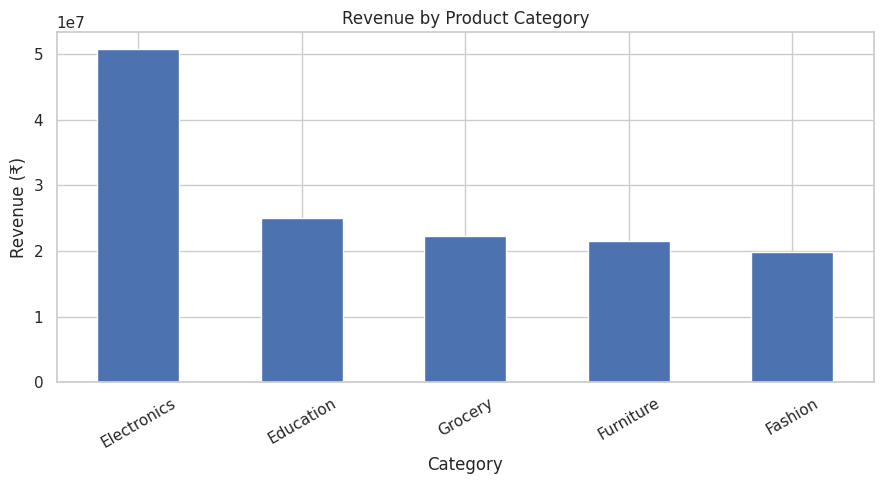

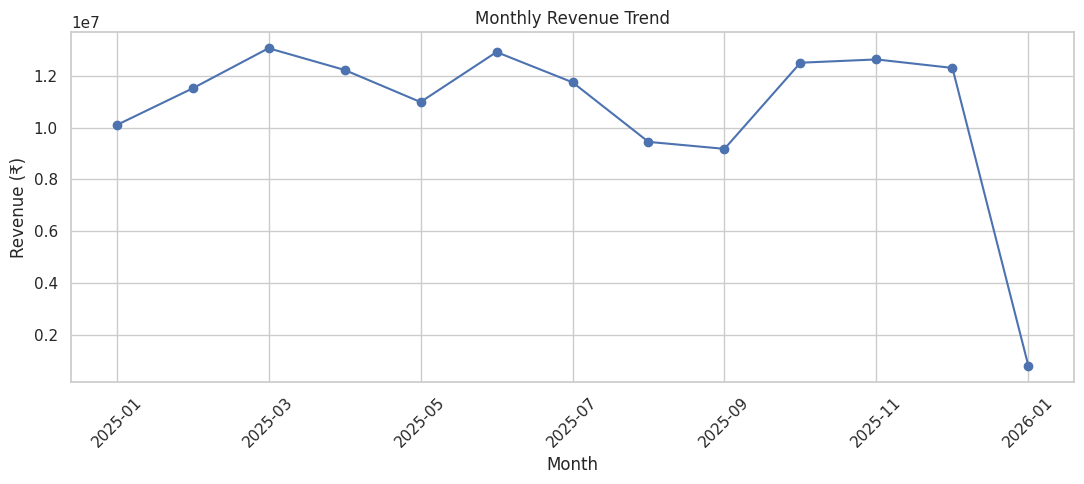

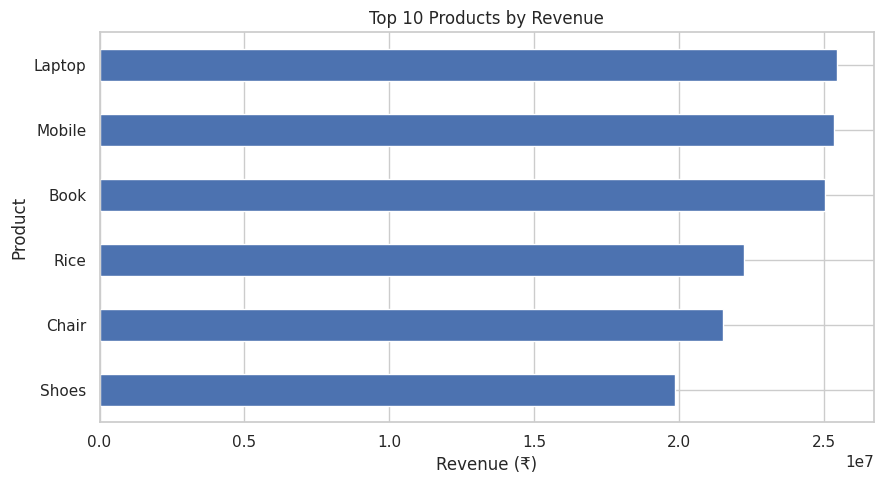

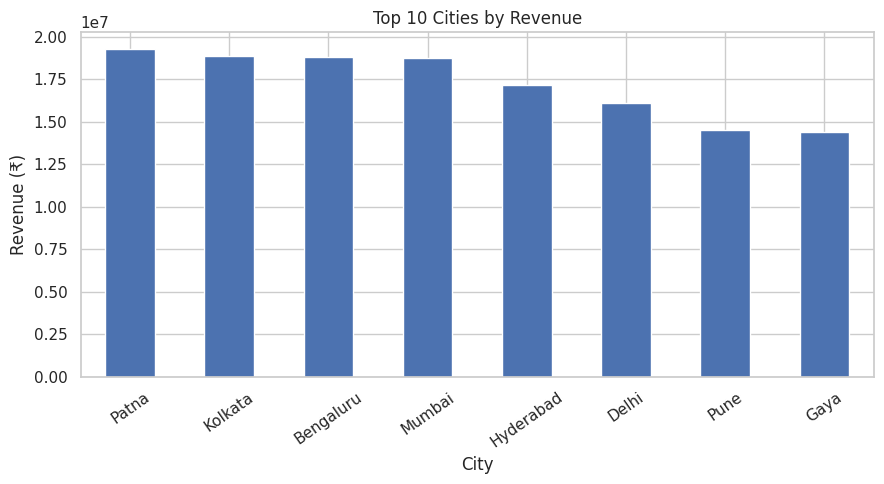

In [5]:
# 1. Revenue by Category
plt.figure(figsize=(9, 5))
category_sales.plot(kind="bar")
plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# 2. Monthly Revenue Trend
plt.figure(figsize=(11, 5))
monthly_sales.plot(marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 3. Top 10 Products
plt.figure(figsize=(9, 5))
top_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (₹)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


# 4. Revenue by City
plt.figure(figsize=(9, 5))
city_sales.plot(kind="bar")
plt.title("Top 10 Cities by Revenue")
plt.xlabel("City")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

**Step 6: Formulate the research hypothesis**

For this project, I will investigate whether the average transaction revenue differs between Electronics and Fashion.

Research question: Is there a significant difference in average transaction revenue between Electronics and Fashion?
- Null Hypothesis (H₀): There is no statistically significant difference in average transaction revenue between Electronics and Fashion.
- Alternative Hypothesis (H₁): There is a statistically significant difference in average transaction revenue between Electronics and Fashion.
- Significance level: 0.05 (5%).
- Statistical test: Welch's independent-samples t-test, provided the observations can be treated as independent.

In [6]:
print("RESEARCH HYPOTHESIS")
print("H0: Average transaction revenue is equal for Electronics and Fashion.")
print("H1: Average transaction revenue differs between Electronics and Fashion.")
print("\nSignificance Level: 0.05")
print("Proposed Test: Welch's Independent-Samples T-Test")

RESEARCH HYPOTHESIS
H0: Average transaction revenue is equal for Electronics and Fashion.
H1: Average transaction revenue differs between Electronics and Fashion.

Significance Level: 0.05
Proposed Test: Welch's Independent-Samples T-Test


**Step 7: Check repeated orders before testing**

In [7]:
# Keep only the two categories being compared
test_data = df[
    df["Category"].isin(["Electronics", "Fashion"])
].copy()

# Remove rows missing essential test information
test_data = test_data.dropna(
    subset=["Order_ID", "Category", "Total_Sales"]
)

# Count how many of the two categories appear in each order
category_count_per_order = (
    test_data.groupby("Order_ID")["Category"].nunique()
)

# Find orders containing both categories
mixed_orders = category_count_per_order[
    category_count_per_order > 1
].index

print("Orders containing both Electronics and Fashion:", len(mixed_orders))

# Exclude mixed-category orders
test_data = test_data[
    ~test_data["Order_ID"].isin(mixed_orders)
]

# Combine multiple rows from the same order and category
order_level_sales = (
    test_data.groupby(["Order_ID", "Category"], as_index=False)
    ["Total_Sales"].sum()
)

print("\nOrder-level observations:")
display(order_level_sales.head())

print("\nObservations by category:")
display(
    order_level_sales.groupby("Category")["Total_Sales"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

Orders containing both Electronics and Fashion: 0

Order-level observations:


,Order_ID,Category,Total_Sales
0,ORD100005,Electronics,256872.24
1,ORD100007,Electronics,323527.23
2,ORD100008,Electronics,299985.18
3,ORD100009,Electronics,28466.49
4,ORD100011,Electronics,144194.72



Observations by category:


,count,mean,median,std
Category,,,,
Electronics,353,143848.67,115263.96,117637.54
Fashion,156,127153.18,101570.32,105149.54


**Step 8: Perform Welch's t-test**

In [8]:
# Separate the order-level revenue values
electronics = order_level_sales.loc[
    order_level_sales["Category"] == "Electronics",
    "Total_Sales"
]

fashion = order_level_sales.loc[
    order_level_sales["Category"] == "Fashion",
    "Total_Sales"
]

print("Electronics observations:", len(electronics))
print("Fashion observations:", len(fashion))

# Check that both groups have enough observations
if len(electronics) < 2 or len(fashion) < 2:
    raise ValueError(
        "Not enough observations to perform the t-test."
    )

# Welch's independent-samples t-test
t_statistic, p_value = ttest_ind(
    electronics,
    fashion,
    equal_var=False
)

print("\nWELCH'S T-TEST RESULTS")
print("T-statistic:", round(t_statistic, 4))
print("P-value:", round(p_value, 6))

Electronics observations: 353
Fashion observations: 156

WELCH'S T-TEST RESULTS
T-statistic: 1.5913
P-value: 0.112502


**Step 9: Calculate the 95% confidence interval**

In [9]:
# Group statistics
mean_e = electronics.mean()
mean_f = fashion.mean()

var_e = electronics.var(ddof=1)
var_f = fashion.var(ddof=1)

n_e = len(electronics)
n_f = len(fashion)

# Difference in means
mean_difference = mean_e - mean_f

# Standard error for Welch's test
standard_error = sqrt(
    (var_e / n_e) + (var_f / n_f)
)

# Welch-Satterthwaite degrees of freedom
df_welch = (
    ((var_e / n_e) + (var_f / n_f)) ** 2
    /
    (
        ((var_e / n_e) ** 2 / (n_e - 1))
        +
        ((var_f / n_f) ** 2 / (n_f - 1))
    )
)

# 95% confidence interval
critical_value = t.ppf(0.975, df_welch)

lower_limit = mean_difference - critical_value * standard_error
upper_limit = mean_difference + critical_value * standard_error

print("Electronics Mean Revenue: ₹", round(mean_e, 2))
print("Fashion Mean Revenue: ₹", round(mean_f, 2))
print("Difference in Means: ₹", round(mean_difference, 2))

print(
    "95% Confidence Interval: ₹",
    round(lower_limit, 2),
    "to ₹",
    round(upper_limit, 2)
)

Electronics Mean Revenue: ₹ 143848.67
Fashion Mean Revenue: ₹ 127153.18
Difference in Means: ₹ 16695.5
95% Confidence Interval: ₹ -3943.81 to ₹ 37334.8


**Step 10: Interpret the statistical results**

In [10]:
alpha = 0.05

print("HYPOTHESIS TEST INTERPRETATION")
print("--------------------------------")

if p_value < alpha:
    print("Decision: Reject the Null Hypothesis (H0).")
    print(
        "Conclusion: There is statistically significant "
        "evidence of a difference in average transaction "
        "revenue between Electronics and Fashion."
    )
else:
    print("Decision: Fail to Reject the Null Hypothesis (H0).")
    print(
        "Conclusion: There is insufficient statistical "
        "evidence of a difference in average transaction "
        "revenue between Electronics and Fashion."
    )

print("\nP-value:", round(p_value, 6))
print("Significance Level:", alpha)

HYPOTHESIS TEST INTERPRETATION
--------------------------------
Decision: Fail to Reject the Null Hypothesis (H0).
Conclusion: There is insufficient statistical evidence of a difference in average transaction revenue between Electronics and Fashion.

P-value: 0.112502
Significance Level: 0.05


**Step 11: Create a comparison chart**

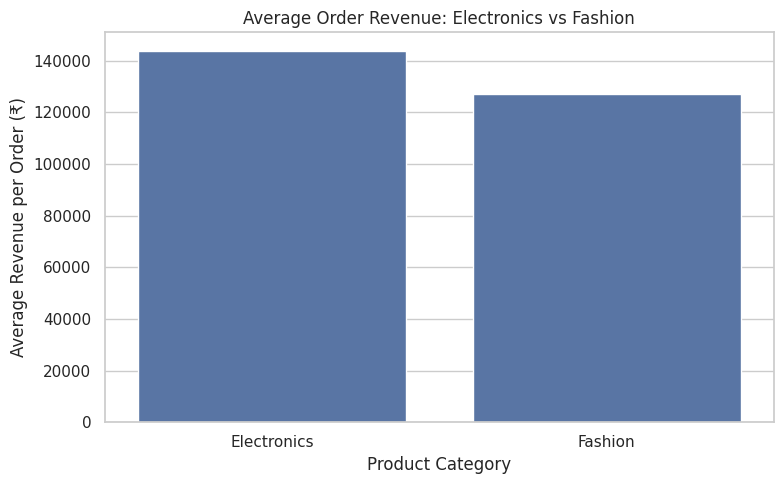

In [11]:
comparison_data = pd.DataFrame({
    "Category": ["Electronics", "Fashion"],
    "Average Revenue": [mean_e, mean_f]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison_data,
    x="Category",
    y="Average Revenue"
)

plt.title("Average Order Revenue: Electronics vs Fashion")
plt.xlabel("Product Category")
plt.ylabel("Average Revenue per Order (₹)")

plt.tight_layout()
plt.show()

**Step 12: Save the Task 4 results**

In [21]:
final_hypothesis_summary = pd.DataFrame({
    "Metric": [
        "Research Question",
        "Statistical Test",
        "Significance Level",
        "Electronics-only Customers",
        "Fashion-only Customers",
        "Electronics Average",
        "Fashion Average",
        "Difference in Averages",
        "T-statistic",
        "P-value",
        "95% CI Lower Limit",
        "95% CI Upper Limit",
        "Decision"
    ],
    "Result": [
        "Difference in average order revenue per customer",
        "Welch's Independent-Samples T-Test",
        0.05,
        344,
        149,
        143621.03,
        129713.92,
        13907.12,
        1.3045,
        0.193027,
        -7069.57,
        34883.80,
        "Fail to Reject H0"
    ]
})

display(final_hypothesis_summary)

final_hypothesis_summary.to_csv(
    "task4_hypothesis_testing_summary.csv",
    index=False
)

print("Final hypothesis summary saved successfully!")

,Metric,Result
0,Research Question,Difference in average order revenue per customer
1,Statistical Test,Welch's Independent-Samples T-Test
2,Significance Level,0.05
3,Electronics-only Customers,344
4,Fashion-only Customers,149
5,Electronics Average,143621.03
6,Fashion Average,129713.92
7,Difference in Averages,13907.12
8,T-statistic,1.3045
9,P-value,0.193027


Final hypothesis summary saved successfully!


To download the summary:

In [22]:
from google.colab import files

files.download("task4_hypothesis_testing_summary.csv")
files.download("task4_order_level_sales.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Step 13: Prepare your business story**

In [14]:
print("BUSINESS STORY")
print("--------------------------------")

print(f"Total Business Revenue: ₹{total_revenue:,.2f}")
print(f"Total Unique Orders: {total_orders}")
print(f"Total Customers: {total_customers}")

print(
    f"\nHighest Revenue Category: {category_sales.idxmax()}"
)

print(
    f"Highest Revenue Product: {df.groupby('Product')['Total_Sales'].sum().idxmax()}"
)

print(
    f"Highest Revenue City: {city_sales.idxmax()}"
)

print("\nSTATISTICAL FINDING")

if p_value < alpha:
    print(
        "The analysis found a statistically significant "
        "difference in average transaction revenue "
        "between Electronics and Fashion."
    )
else:
    print(
        "The analysis did not find sufficient statistical "
        "evidence of a difference in average transaction "
        "revenue between Electronics and Fashion."
    )

BUSINESS STORY
--------------------------------
Total Business Revenue: ₹139,399,439.65
Total Unique Orders: 992
Total Customers: 947

Highest Revenue Category: Electronics
Highest Revenue Product: Laptop
Highest Revenue City: Patna

STATISTICAL FINDING
The analysis did not find sufficient statistical evidence of a difference in average transaction revenue between Electronics and Fashion.


In [15]:
# Check repeated customers in the two categories

customer_order_count = (
    order_level_sales
    .merge(
        df[["Order_ID", "Customer_ID"]].drop_duplicates(),
        on="Order_ID",
        how="left"
    )
    .groupby(["Category", "Customer_ID"])["Order_ID"]
    .nunique()
    .reset_index(name="Number_of_Orders")
)

print("Customers with multiple orders in each category:")
display(
    customer_order_count[
        customer_order_count["Number_of_Orders"] > 1
    ].groupby("Category").size()
)

print("\nTotal customers with multiple orders:")
display(
    customer_order_count[
        customer_order_count["Number_of_Orders"] > 1
    ].groupby("Category")["Customer_ID"].nunique()
)

Customers with multiple orders in each category:


,0
Category,
Electronics,10



Total customers with multiple orders:


,Customer_ID
Category,
Electronics,10


In [16]:
# Combine order revenue at customer and category level

customer_level_sales = (
    order_level_sales
    .merge(
        df[["Order_ID", "Customer_ID"]].drop_duplicates(),
        on="Order_ID",
        how="left"
    )
    .groupby(["Customer_ID", "Category"], as_index=False)
    ["Total_Sales"].mean()
)

print("Customer-level observations:")
display(customer_level_sales.head())

print("\nNumber of customers in each category:")
display(
    customer_level_sales.groupby("Category")["Customer_ID"]
    .nunique()
)

print("\nCustomer-level revenue summary:")
display(
    customer_level_sales.groupby("Category")["Total_Sales"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

Customer-level observations:


,Customer_ID,Category,Total_Sales
0,CUST1004,Electronics,8321.54
1,CUST1017,Fashion,264230.68
2,CUST1032,Electronics,146990.90
3,CUST1088,Fashion,203819.75
4,CUST1090,Fashion,5263.79



Number of customers in each category:


,Customer_ID
Category,
Electronics,351
Fashion,156



Customer-level revenue summary:


,count,mean,median,std
Category,,,,
Electronics,351,144066.24,118857.45,115931.92
Fashion,156,127153.18,101570.32,105149.54


In [17]:
# Separate customer-level revenue values

electronics_customers = customer_level_sales.loc[
    customer_level_sales["Category"] == "Electronics",
    "Total_Sales"
]

fashion_customers = customer_level_sales.loc[
    customer_level_sales["Category"] == "Fashion",
    "Total_Sales"
]

# Welch's t-test at customer level

customer_t_stat, customer_p_value = ttest_ind(
    electronics_customers,
    fashion_customers,
    equal_var=False
)

print("CUSTOMER-LEVEL WELCH'S T-TEST")
print("--------------------------------")

print("T-statistic:", round(customer_t_stat, 4))
print("P-value:", round(customer_p_value, 6))

if customer_p_value < 0.05:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to Reject H0")

CUSTOMER-LEVEL WELCH'S T-TEST
--------------------------------
T-statistic: 1.6187
P-value: 0.10647
Decision: Fail to Reject H0


In [18]:
# Find customers who purchased from both categories

customer_categories = (
    customer_level_sales.groupby("Customer_ID")["Category"]
    .nunique()
)

overlapping_customers = customer_categories[
    customer_categories > 1
]

electronics_only = (
    customer_level_sales[
        customer_level_sales["Category"] == "Electronics"
    ]["Customer_ID"].nunique()
)

fashion_only = (
    customer_level_sales[
        customer_level_sales["Category"] == "Fashion"
    ]["Customer_ID"].nunique()
)

print("Customers purchasing both categories:",
      len(overlapping_customers))

print("Electronics customers:", electronics_only)
print("Fashion customers:", fashion_only)

Customers purchasing both categories: 7
Electronics customers: 351
Fashion customers: 156


In [19]:
# Remove customers who purchased from both categories

independent_customer_data = customer_level_sales[
    ~customer_level_sales["Customer_ID"].isin(
        overlapping_customers.index
    )
].copy()

# Separate the two independent groups

electronics_only_data = independent_customer_data[
    independent_customer_data["Category"] == "Electronics"
]["Total_Sales"]

fashion_only_data = independent_customer_data[
    independent_customer_data["Category"] == "Fashion"
]["Total_Sales"]

print("Electronics-only customers:", len(electronics_only_data))
print("Fashion-only customers:", len(fashion_only_data))

Electronics-only customers: 344
Fashion-only customers: 149


In [20]:
from scipy.stats import ttest_ind, t
from math import sqrt

# Perform Welch's independent-samples t-test

final_t_stat, final_p_value = ttest_ind(
    electronics_only_data,
    fashion_only_data,
    equal_var=False
)

# Calculate group statistics

mean_e = electronics_only_data.mean()
mean_f = fashion_only_data.mean()

var_e = electronics_only_data.var(ddof=1)
var_f = fashion_only_data.var(ddof=1)

n_e = len(electronics_only_data)
n_f = len(fashion_only_data)

mean_difference = mean_e - mean_f

# Calculate standard error

standard_error = sqrt(
    (var_e / n_e) + (var_f / n_f)
)

# Calculate degrees of freedom

degrees_freedom = (
    ((var_e / n_e) + (var_f / n_f)) ** 2
    /
    (
        ((var_e / n_e) ** 2 / (n_e - 1))
        +
        ((var_f / n_f) ** 2 / (n_f - 1))
    )
)

# Calculate 95% confidence interval

critical_value = t.ppf(0.975, degrees_freedom)

lower_limit = mean_difference - critical_value * standard_error
upper_limit = mean_difference + critical_value * standard_error

# Display final results

print("FINAL HYPOTHESIS TEST RESULTS")
print("--------------------------------")

print("Electronics-only customers:", n_e)
print("Fashion-only customers:", n_f)

print("\nElectronics average:", round(mean_e, 2))
print("Fashion average:", round(mean_f, 2))

print("Difference in averages:", round(mean_difference, 2))
print("T-statistic:", round(final_t_stat, 4))
print("P-value:", round(final_p_value, 6))

print(
    "95% Confidence Interval:",
    round(lower_limit, 2),
    "to",
    round(upper_limit, 2)
)

if final_p_value < 0.05:
    print("\nDecision: Reject H0")
else:
    print("\nDecision: Fail to Reject H0")

FINAL HYPOTHESIS TEST RESULTS
--------------------------------
Electronics-only customers: 344
Fashion-only customers: 149

Electronics average: 143621.03
Fashion average: 129713.92
Difference in averages: 13907.12
T-statistic: 1.3045
P-value: 0.193027
95% Confidence Interval: -7069.57 to 34883.8

Decision: Fail to Reject H0
